Imports and Paths

In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data/processed")
# Step 1's output lives here
FIG = Path("../figures")

Loading saved file and filter and sensor columns

In [16]:
import os
from pathlib import Path
print("Current Working Directory:", Path.cwd())
print("DATA path resolves to:", (Path.cwd() / DATA).resolve())
print("Does file exist?", (DATA / "secom_tidy.csv").exists())

Current Working Directory: /home/eli/Dev/secom-spc/notebooks
DATA path resolves to: /home/eli/Dev/secom-spc/data/processed
Does file exist? True


In [18]:
# 1. Load the data
df = pd.read_csv(DATA / "secom_tidy.csv", parse_dates=["timestamp"])

# 2. Clean column names (removes any '[' or ']' brackets)
df.columns = [c.replace("[", "").replace("]", "") for c in df.columns]

# 3. Save the clean file back to disk so all future steps have it
df.to_csv(DATA / "secom_tidy.csv", index=False)

# 4. Check the sensors and splits
sensors = [c for c in df.columns if c[0] == "s" and c[1:].isdigit()]
train = df[df["split"] == "train"]
test = df[df["split"] == "test"]
print(len(sensors), "sensors;", len(train), "train runs;", len(test), "test runs")

590 sensors; 1096 train runs; 471 test runs


In [19]:
df = pd.read_csv(DATA / "secom_tidy.csv", parse_dates=["timestamp"])
sensors = [c for c in df.columns if c[0] == "s" and c[1:].isdigit()]
train = df[df["split"] == "train"]
test = df[df["split"] == "test"]
print(len(sensors), "sensors;", len(train), "train runs;", len(test), "test runs")

590 sensors; 1096 train runs; 471 test runs


Drop list from training rows only

- only using the 1096 training rows, never test
- if a sensor has > 50% missing values in training, drop
- if sensor has zero sd or is all-NaN in training, drop

In [20]:
miss_train = train[sensors].isna().mean()
# fraction missing per sensor, training rows only
std_train = train[sensors].std()
# spread per sensor, training rows only
drop_missing = miss_train[miss_train > 0.5].index
# more than half missing: filling the gaps would invent most of the data
drop_constant = std_train[(std_train == 0) | std_train.isna()].index
# no spread in training = nothing to learn from (| means "or")
drop = set(drop_missing) | set(drop_constant)
# a set holds each name once; | joins the two sets
keep = [s for s in sensors if s not in drop]
# the sensors that survive, in their original order
print("drop for missing:", len(drop_missing))
print("drop for constant:", len(drop_constant))
print("dropped total:", len(drop), " kept:", len(keep))

drop for missing: 24
drop for constant: 122
dropped total: 146  kept: 444


Now fill gaps with training medians

- compute the median of each of the 444 surviving runs of the 590 sensors using the training data. Median instead of mean so outliers wont distort
- use the training medians, so test data never computes its own medians
- check that zero missing values remian in either matrix

In [21]:
medians = train[keep].median()
# one median per kept sensor, from training rows; median resists the big outliers in fab data
X_train = train[keep].fillna(medians)
# fillna with a Series fills each column with its own median
X_test = test[keep].fillna(medians)
# the test rows get the TRAINING medians, never their own
print("missing left:", X_train.isna().sum().sum(), X_test.isna().sum().sum())

missing left: 0 0


Save tables

In [22]:
info = ["timestamp", "fail"]
pd.concat([train[info], X_train], axis=1).to_csv(DATA / "clean_train.csv", index=False)
# timestamp + fail + 444 cleaned sensors
pd.concat([test[info], X_test], axis=1).to_csv(DATA / "clean_test.csv", index=False)
print(pd.read_csv(DATA / "clean_train.csv").shape, pd.read_csv(DATA / "clean_test.csv").shape)

(1096, 446) (471, 446)


I-MR Limit function

In [24]:
def imr_limits(x):
    """Phase I I-MR limits from a baseline series x."""
    x = np.asarray(x, dtype=float)
    # accept a list or a pandas column; work in a plain float array
    mr = np.abs(np.diff(x))
    # np.diff gives x[1]-x[0], x[2]-x[1], ... ; abs makes them ranges
    mr_bar = mr.mean()
    sigma = mr_bar / 1.128
    # sigma from successive differences: a slow drift inflates this much less than std(x)
    center = x.mean()
    return {"center": center, "sigma": sigma,
            "UCL": center + 3 * sigma, "LCL": center - 3 * sigma,
            "MR_bar": mr_bar, "MR_UCL": 3.267 * mr_bar}
    # a dict: named results, like a small labelled table

check = imr_limits([10, 12, 11, 13, 12])
# toy series you can do by hand: MR = 2, 1, 2, 1


In statistical process control, an I-MR chart is used when data consists of single runs rather than grouped samples (subgroup size n = 1).

Key formulas:
- Moving range: MR = absolute difference between consecutive runs |x_i - x_i-1|
- Average moving range: MR_avg = average of all moving ranges
- Short-term standard deviation: sigma_est = MR_avg / d2, where d2 = 1.128 for pairs of points
- Individual chart limits: center = mean of x, UCL = mean of x + 3 * sigma_est, LCL = mean of x - 3 * sigma_est
- Moving range chart limits: center = MR_avg, UCL = 3.267 * MR_avg, LCL = 0

Why sigma_est = MR_avg / d2 instead of standard deviation?
- The ordinary standard deviation measures overall spread across all time.
- If the machine drifts or has a step change, the standard deviation gets inflated, making the control limits too wide to catch bad runs.
- Successive differences isolate the true short-term noise between back-to-back runs.

In [25]:
print({k: round(float(v), 4) for k, v in check.items()})
# float() turns numpy numbers into plain ones so they print cleanly

{'center': 11.6, 'sigma': 1.3298, 'UCL': 15.5894, 'LCL': 7.6106, 'MR_bar': 1.5, 'MR_UCL': 4.9005}


Limits for Sensor s059

- in training data, s059 has strongest statisticla link to wafer failure of all 444 sensors

In [27]:
s = "s059"
lim = imr_limits(X_train[s])
# Phase I: limits from the training runs only
print({k: round(float(v), 4) for k, v in lim.items()})

{'center': 4.4881, 'sigma': 6.2942, 'UCL': 23.3707, 'LCL': -14.3945, 'MR_bar': 7.0999, 'MR_UCL': 23.1952}


found the phase 1 contorl limits for sensor s059 using only the 1096 historical training runs

I-MR Chart over Train + Test

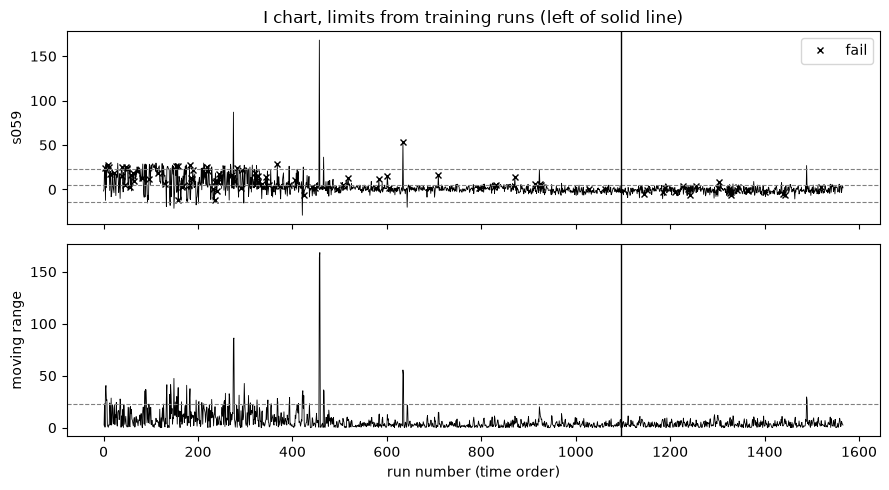

In [28]:
x_all = pd.concat([X_train[s], X_test[s]]).to_numpy()
# the whole series in time order: training runs, then test runs
fail_all = pd.concat([train["fail"], test["fail"]]).to_numpy()
n_tr = len(X_train)
# where training ends (vertical line on the plot)
t = np.arange(len(x_all))
# run number 0, 1, 2, ... = time order
mr_all = np.abs(np.diff(x_all))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
# two stacked plots sharing the x axis: I chart on top, MR chart below
ax1.plot(t, x_all, color="black", lw=0.6)
ax1.plot(t[fail_all == 1], x_all[fail_all == 1], "x", color="black", ms=5, label="fail")
# mark the failed runs with an x
for v in (lim["UCL"], lim["center"], lim["LCL"]):
    ax1.axhline(v, color="gray", ls="--", lw=0.8)
    # dashed horizontal lines for the limits
ax1.axvline(n_tr, color="black", lw=1)
ax1.set_ylabel(s)
ax1.legend(loc="upper right")
ax1.set_title("I chart, limits from training runs (left of solid line)")
ax2.plot(t[1:], mr_all, color="black", lw=0.6)
# MR starts at the second run
ax2.axhline(lim["MR_UCL"], color="gray", ls="--", lw=0.8)
ax2.axvline(n_tr, color="black", lw=1)
ax2.set_ylabel("moving range")
ax2.set_xlabel("run number (time order)")
fig.tight_layout()
fig.savefig(FIG / "imr_s059.png", dpi=150)
plt.show()

- Process change shown at run 480, variance drops, so less failure markers passed that
- This shows that traditional SPC fails when the first phase of historical data is not collected from a stable, in control baseline. The limits are overinflated based on that noisy period
- Because of this, when applying the limits to the testing regime, past the black bar, we see that process has already shifted to the lower noise, and the limits are too wide

What the chart says about fails, training and testing

In [29]:
out_train = (X_train[s] > lim["UCL"]) | (X_train[s] < lim["LCL"])
# True where a training run is outside the I-chart limits
out_test = (X_test[s] > lim["UCL"]) | (X_test[s] < lim["LCL"])
print("train points outside:", out_train.sum(), "of", len(out_train))
print("test points outside: ", out_test.sum(), "of", len(out_test))
print("fail rate when outside (train):", round(train.loc[out_train, "fail"].mean(), 3))
# .loc[mask, col]: rows where mask is True
print("fail rate when inside  (train):", round(train.loc[~out_train, "fail"].mean(), 3))
# ~ flips True/False
before = train["timestamp"] < "2008-08-28 13:00"
# the regime change you see on the chart
print("fail rate before / after Aug 28:", round(train.loc[before, "fail"].mean(), 3),
      round(train.loc[~before, "fail"].mean(), 3))
print("s059 std before / after:", round(X_train.loc[before, s].std(), 2),
      round(X_train.loc[~before, s].std(), 2))

train points outside: 87 of 1096
test points outside:  1 of 471
fail rate when outside (train): 0.149
fail rate when inside  (train): 0.064
fail rate before / after Aug 28: 0.121 0.032
s059 std before / after: 14.14 4.11


What would happen if all sensor charts go at once?

In [30]:
limits = pd.DataFrame({c: imr_limits(X_train[c]) for c in keep}).T
# one row of limits per sensor; .T flips so sensors are rows
outside = (X_test > limits["UCL"]) | (X_test < limits["LCL"])
# pandas lines up each test column with its own sensor's limits
print("charts:", len(keep))
print("test runs with at least 1 alarm:", round(outside.any(axis=1).mean(), 3))
# any(axis=1): did any sensor alarm on this run?
print("average alarms per test run:", round(outside.sum(axis=1).mean(), 1))
print("expected if every chart were in control:", round(1 - 0.9973 ** len(keep), 3))
# chance a run has at least one false alarm across 444 independent 3-sigma charts
fail_te = test["fail"].to_numpy() == 1
print("alarm rate, test fails:", round(outside[fail_te].any(axis=1).mean(), 3))
print("alarm rate, test passes:", round(outside[~fail_te].any(axis=1).mean(), 3))

charts: 444
test runs with at least 1 alarm: 1.0
average alarms per test run: 15.8
expected if every chart were in control: 0.699
alarm rate, test fails: 1.0
alarm rate, test passes: 1.0


If there is a below 1% chance for each sensor chart to have a false alarm, across the full process, almost 100% of the runs would have a false alarm. In this case:
- there were no runs without atleast 1 alarm
- each run triggers atleast 15.8 alarms
- zero actionable information

This shows the need for use of Multivariate Statistical Process Control (MSPC)

Export first 30 vales of s059 as csv

In [32]:
X_train[s].head(30).to_csv(DATA / "s059_first30.csv", index=False)
# the first 30 training values of s059
print({k: round(float(v), 4) for k, v in imr_limits(X_train[s].head(30)).items()})

{'center': 11.5668, 'sigma': 11.4321, 'UCL': 45.8631, 'LCL': -22.7295, 'MR_bar': 12.8954, 'MR_UCL': 42.1293}


- Training-only cleaning rules: Cleaning dropped 24 sensors with over 50 percent missing data and 122 constant sensors with zero variance, leaving 444 usable sensors. Determining these drop lists and filling missing gaps using only the 1,096 training runs prevents future test data from leaking into preprocessing.
- Regime change on s059: Sensor s059, the sensor most correlated with wafer failures in training, shows a sudden process shift around August 28 (run 480). Its standard deviation drops from 14.14 down to 4.11, which directly lines up with the wafer failure rate dropping from 12.1 percent to 3.2 percent.
- Baseline not in control: Phase 1 I-MR control limits assume an in-control, stable baseline. However, 87 out of 1,096 training runs fall outside 3-sigma limits, far above the theoretical 0.27 percent (about 3 runs) expected from a normal process, proving the baseline process was inherently unstable.
- False alarm flood: Running 444 separate univariate charts at once causes a massive multiple testing breakdown. Every single test run (100 percent) triggers at least one alarm, averaging 15.8 alarms per run on both passing and failing wafers, providing zero actionable signal and proving the need for multivariate monitoring like PCA.